[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB13_reproducing_rest.ipynb)

# Day 2 · Chapter 5 · Notebook 13 — Reproducing the resting brain

> **What we do.** The solution of the NB10 task, pre-run (shown right after NB10): the same simulator, the same
> similarity score and the same 3 runs per point, so at the same $a$ (distance to the bifurcation) and $G$ (coupling)
> the numbers are exactly those of NB10. We add the second target of NB09, **dynamic FC**.
> **Look at:** where the good fits of each target sit with respect to the bifurcation ($a=0$).

Targets: the FC is the HCP group at rest; the dynamic FC comes from the BOLD of NB09 (10 adults, 18–31 years, watching
a short film). Pre-run: results are displayed; running it again takes about two minutes.

In [1]:
# @title Setup: data, the fast Hopf simulator, FC and dynamic FC measures
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import connectome, bold
from matplotlib.colors import TwoSlopeNorm
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="rowsum", homotopic=0.5)   # same connectome as NB10
ts = np.load("../data/empirical/fmri_ds000228_schaefer100.npz")["ts"]                      # BOLD of NB09, 10 people
net = np.array([l.split("_")[2] for l in labels])                  # resting-state network of each region
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
order = np.concatenate([np.where(net == n)[0] for n in NETS])     # regions sorted by network, for display
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]

def show_matrix(ax, M, title, labels_on=True, **kw):
    # FC matrix, regions grouped by network (as in NB09-NB10)
    im = ax.imshow(M[np.ix_(order, order)], **kw); ax.set_title(title)
    sizes = [np.sum(net == n) for n in NETS]; mids = np.cumsum([0] + sizes)
    for e in mids[1:-1] - 0.5: ax.axhline(e, c="k", lw=0.4); ax.axvline(e, c="k", lw=0.4)
    ax.set_xticks([]); ax.set_yticks((mids[:-1] + mids[1:]) / 2 - 0.5, NETS if labels_on else [], fontsize=7)
    return im

def simulate(a, G, sigma=0.02, minutes=20, seed=0, f=0.05, dt=0.1, TR=2.0):
    # the simulator of NB10, unchanged: Hopf oscillator in every region, coupled through the connectome
    rng = np.random.default_rng(seed)
    N = len(sc); strength = sc.sum(1); omega = 2 * np.pi * f
    z = 0.1 * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
    every, n_skip = int(TR / dt), int(60 / dt)
    out = []
    for k in range(n_skip + int(minutes * 60 / dt)):
        local = (a + 1j * omega) * z - np.abs(z) ** 2 * z
        coupling = G * (sc @ z - strength * z)
        noise = sigma * np.sqrt(dt) * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
        z = z + dt * (local + coupling) + noise
        if k >= n_skip and (k - n_skip) % every == every - 1:
            out.append(z.real)
    x = np.array(out)
    return np.arange(len(x)) * TR, x

def model_fc(a, G, runs=3):
    # FC of the model averaged over 3 runs of 20 minutes (seeds 0-2), as fc_similarity in NB10
    return np.mean([np.corrcoef(simulate(a, G, seed=s)[1].T) for s in range(runs)], 0)

def dynamic_fc(x, w=30, step=2):
    # as in NB09: similarity of the FC of every pair of 60-s windows, and the values for non-overlapping pairs
    F = np.array([np.corrcoef(x[s:s + w].T)[u] for s in range(0, len(x) - w + 1, step)]); D = np.corrcoef(F)
    far = np.abs(np.subtract.outer(np.arange(len(F)), np.arange(len(F)))) * step >= w
    return D, D[np.triu(far)]

def model_runs(a, G, n=10):
    # n runs as long as the recordings (5.6 min), band-passed like the data
    return [bold.bandpass(simulate(a, G, minutes=5.6, seed=10 + s)[1], 2.0) for s in range(n)]

dfc_data = np.concatenate([dynamic_fc(x)[1] for x in ts])
print(f"dynamic FC of the data (NB09): variance {dfc_data.var():.4f}")

dynamic FC of the data (NB09): variance 0.0096


## 1. Both targets across $a$ and $G$

> **Gist.** For every pair ($a$, $G$): (left) the **FC similarity** with the measured FC, from 3 × 20-minute runs
> (the map of NB10); (right) the **dynamic FC variance**, from 10 runs as long as the recordings, compared with the
> data.

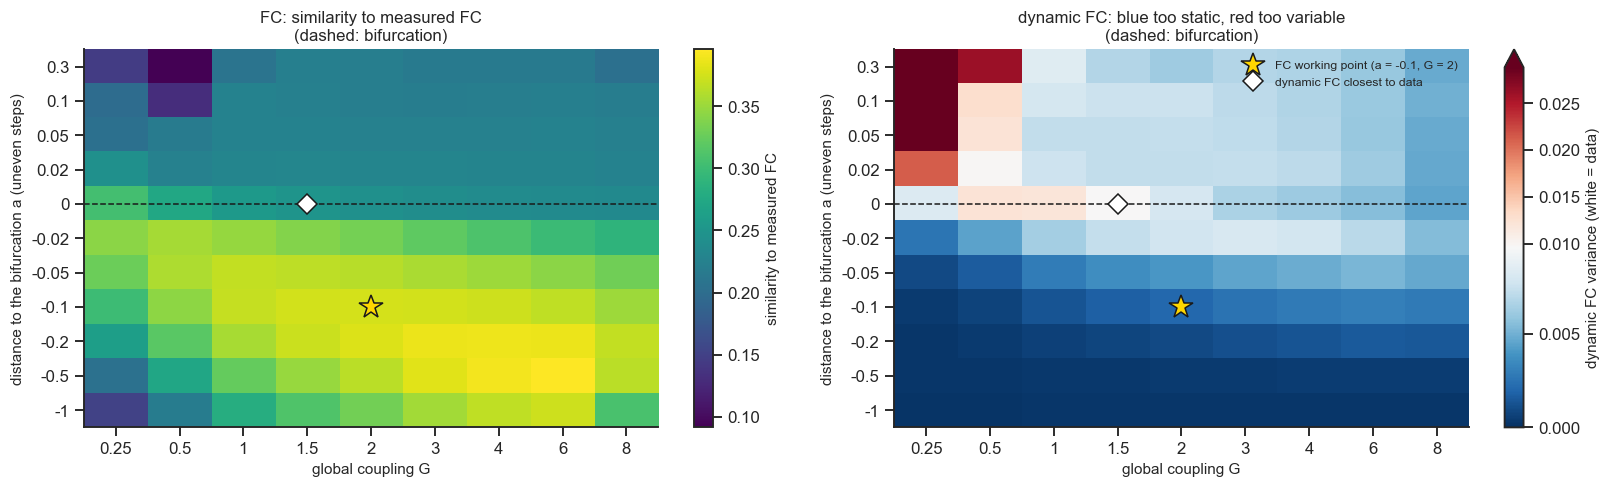

highest FC similarity: 0.396 at a = -0.5, G = 6
FC working point: a = -0.1, G = 2, similarity 0.376, dynamic FC variance 0.0021
just below the bifurcation: a = -0.02, G = 1, similarity 0.348, dynamic FC variance 0.0064
dynamic FC closest to data: a = 0, G = 1.5, variance 0.0096 (data 0.0096), FC similarity 0.25


In [2]:
# @title Sweep a and G: FC similarity and dynamic FC variance (about two minutes)
A_list = np.r_[-1.0, -0.5, -0.2, -0.1, -0.05, -0.02, 0.0, 0.02, 0.05, 0.1, 0.3]
G_list = np.r_[0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8]
fit = np.array([[similarity(model_fc(a, G), fc) for G in G_list] for a in A_list])
dvar = np.array([[np.concatenate([dynamic_fc(x)[1] for x in model_runs(a, G)]).var() for G in G_list] for a in A_list])

i_max = np.unravel_index(np.argmax(fit), fit.shape)                             # highest FC similarity on the grid
i_fc = (list(A_list).index(-0.1), list(G_list).index(2.0))                       # working point used in NB12-NB14 (on the band)
i_dyn = np.unravel_index(np.argmin(np.abs(np.log(dvar / dfc_data.var()))), dvar.shape)   # dynamic FC closest to data
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
im = ax[0].imshow(fit, origin="lower", aspect="auto", cmap="viridis")
plt.colorbar(im, ax=ax[0], label="similarity to measured FC")
im = ax[1].imshow(dvar, origin="lower", aspect="auto", cmap="RdBu_r",
                  norm=TwoSlopeNorm(vcenter=dfc_data.var(), vmin=0, vmax=3 * dfc_data.var()))
plt.colorbar(im, ax=ax[1], label="dynamic FC variance (white = data)", extend="max")
for a_, title in zip(ax, ["FC: similarity to measured FC", "dynamic FC: blue too static, red too variable"]):
    a_.set_xticks(range(len(G_list)), [f"{g:g}" for g in G_list]); a_.set_yticks(range(len(A_list)), [f"{a:g}" for a in A_list])
    a_.axhline(list(A_list).index(0.0), c="k", ls="--", lw=1)
    a_.plot(i_fc[1], i_fc[0], "*", c="gold", mec="k", ms=16, label="FC working point (a = -0.1, G = 2)")
    a_.plot(i_dyn[1], i_dyn[0], "D", c="w", mec="k", ms=9, label="dynamic FC closest to data")
    a_.set(xlabel="global coupling G", ylabel="distance to the bifurcation a (uneven steps)", title=title + "\n(dashed: bifurcation)")
ax[1].legend(fontsize=8, loc="upper right", framealpha=0.9)
plt.tight_layout(); plt.show()
a_fc, G_fc = A_list[i_fc[0]], G_list[i_fc[1]]; a_dyn, G_dyn = A_list[i_dyn[0]], G_list[i_dyn[1]]
print(f"highest FC similarity: {fit[i_max]:.3f} at a = {A_list[i_max[0]]:g}, G = {G_list[i_max[1]]:g}")
print(f"FC working point: a = {a_fc:g}, G = {G_fc:g}, similarity {fit[i_fc]:.3f}, dynamic FC variance {dvar[i_fc]:.4f}")
i_c = (list(A_list).index(-0.02), list(G_list).index(1.0))
print(f"just below the bifurcation: a = -0.02, G = 1, similarity {fit[i_c]:.3f}, dynamic FC variance {dvar[i_c]:.4f}")
print(f"dynamic FC closest to data: a = {a_dyn:g}, G = {G_dyn:g}, variance {dvar[i_dyn]:.4f} (data {dfc_data.var():.4f}), FC similarity {fit[i_dyn]:.2f}")

* **FC (left), the map of NB10:** good fits lie on a diagonal band **below the bifurcation**, reaching a similarity of
  about 0.4; the further below, the stronger the coupling needed. At and above the bifurcation the regions lock and
  the fit drops below the wiring alone (0.32), whatever the coupling. Along the band the differences (0.35–0.40) are
  mostly noise of 3 runs: with 12 runs every cell of the band reaches about 0.40 (NB10 solution). The next notebooks
  use $a=-0.1$, $G=2$ (star), a point of the band.
* **Dynamic FC (right):** far below the bifurcation the model is too **static** (dark blue): every minute has the same
  FC. The variability grows as $a$ approaches 0 and matches the data (white) **near the bifurcation**: at it (diamond),
  or slightly above it with weak coupling ($G\approx0.5$–1); just below it ($a=-0.02$) it comes close with $G\ge1$.
  Above the bifurcation with very weak coupling the regions are independent clocks and the variability overshoots (red).
* **A trade-off.** The point that best matches the dynamic FC (diamond) has an FC similarity of only 0.25, **below the
  wiring alone**; the FC working point (star) is too static. Neither target alone fixes the working point, but
  together they point to regions **just below the bifurcation** ($a\approx-0.02$, $G\approx1$): dynamic FC close to the
  data, and an FC fit of 0.35 with 3 runs that reaches about 0.39 with 12 (NB10 solution; the slow signals near the
  bifurcation need longer simulations). Never far from the bifurcation, never above it (Deco et al. 2017).

## 2. FC at the working point

> **Gist.** The model FC at the working point next to the measured FC, sorted by network.

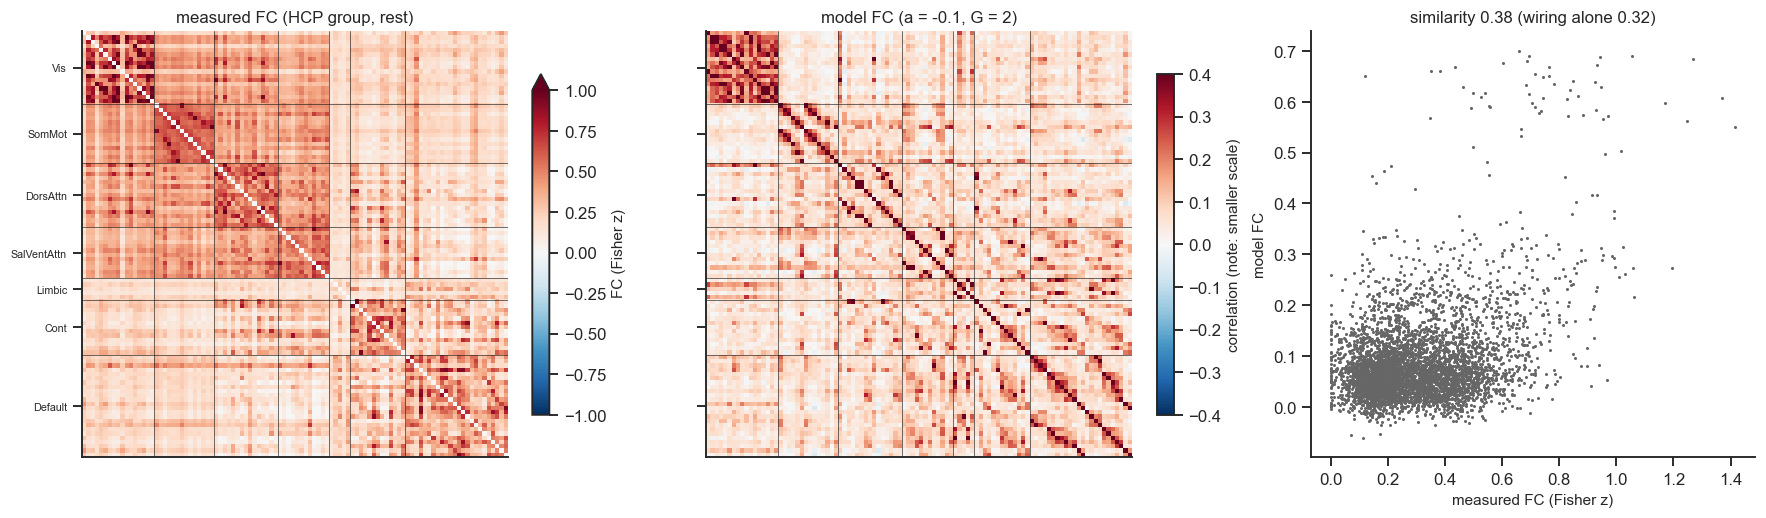

In [3]:
# @title Model FC at the working point vs measured FC
M = model_fc(a_fc, G_fc)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.9]), layout="constrained")
show_matrix(ax[0], fc, "measured FC (HCP group, rest)", cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(ax[0].images[0], ax=ax[0], shrink=0.8, label="FC (Fisher z)", extend="max")
im = show_matrix(ax[1], M, f"model FC (a = {a_fc:g}, G = {G_fc:g})", labels_on=False, cmap="RdBu_r", vmin=-0.4, vmax=0.4)
plt.colorbar(im, ax=ax[1], shrink=0.8, label="correlation (note: smaller scale)")
ax[2].plot(fc[u], M[u], ".", ms=2, c="0.4")
ax[2].set(xlabel="measured FC (Fisher z)", ylabel="model FC", title=f"similarity {similarity(M, fc):.2f} (wiring alone 0.32)")
plt.show()

Model correlations are weaker overall (note the colour scale): the similarity measures the pattern, not the size.
The model recovers the visual block and the strongest direct and mirror links (the separate cloud at the top), but
misses most of the blocks of the association networks: with every region identical the fit stays around 0.4
(regions that differ: NB13b).

## 3. Dynamic FC: the two working points

> **Gist.** The dynamic FC of one person, and of the model at the FC working point and at the point closest to the
> data's dynamic FC (each model run as long as a recording).

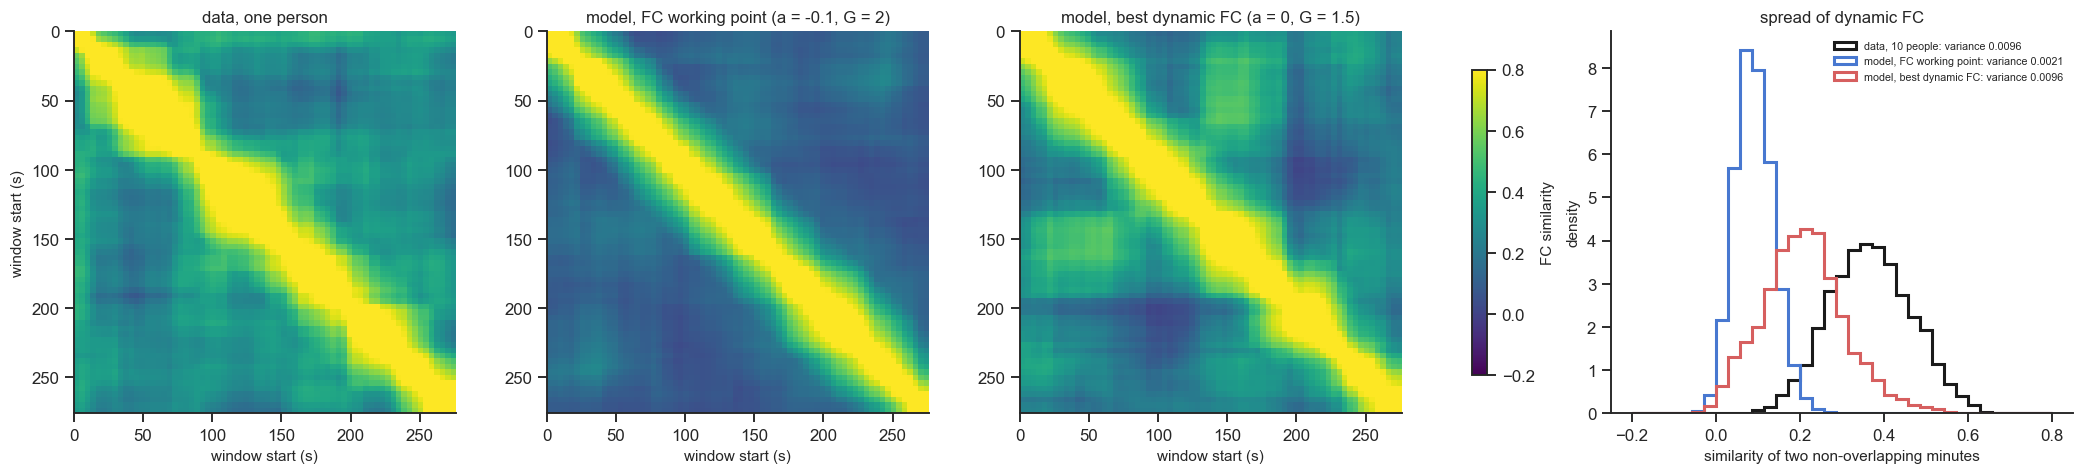

In [4]:
# @title Dynamic FC matrices and distributions: data vs the two model working points
runs_fc, runs_dyn = model_runs(a_fc, G_fc), model_runs(a_dyn, G_dyn)
cases = [("data, one person", ts[0], None, "k"),
         (f"model, FC working point (a = {a_fc:g}, G = {G_fc:g})", runs_fc[0], runs_fc, "C0"),
         (f"model, best dynamic FC (a = {a_dyn:g}, G = {G_dyn:g})", runs_dyn[0], runs_dyn, "C3")]
fig, ax = plt.subplots(1, 4, figsize=(19, 4.2), layout="constrained")
tmax = (len(dynamic_fc(ts[0])[0]) - 1) * 4
for a_, (name, x, runs, c) in zip(ax[:3], cases):
    im = a_.imshow(dynamic_fc(x)[0], cmap="viridis", vmin=-0.2, vmax=0.8, extent=[0, tmax, tmax, 0])
    a_.set(xlabel="window start (s)", ylabel="window start (s)" if a_ is ax[0] else "", title=name)
    vals = dfc_data if runs is None else np.concatenate([dynamic_fc(y)[1] for y in runs])
    ax[3].hist(vals, bins=np.linspace(-0.2, 0.8, 36), density=True, histtype="step", lw=2, color=c,
               label=f"{name.split(' (')[0].replace(', one person', ', 10 people')}: variance {vals.var():.4f}")
plt.colorbar(im, ax=ax[:3], shrink=0.8, label="FC similarity")
ax[3].set(xlabel="similarity of two non-overlapping minutes", ylabel="density", title="spread of dynamic FC")
ax[3].legend(fontsize=7, loc="upper right")
plt.show()

At the FC working point (blue) the model's minutes are almost interchangeable: no structure off the diagonal, a narrow
distribution. At the bifurcation (red) the regions' fluctuations are slow and widely shared (critical slowing down,
NB08), so the FC of one minute drifts from that of the next and the spread approaches the data's (black). The data
curve sits further right: separate minutes of the data are more alike on average, because people watched the same
film and the global signal was not removed (NB09), a shared component that this model does not have. This is why we
compare the spread (variance), not the position of the curves.

<details><summary>Caveats</summary>

Comparing whole distributions (e.g. with a Kolmogorov–Smirnov distance) would reward models that are correlated for
other reasons. With 5.6 minutes per person much of the spread can be sampling noise (NB09, caveats), so the spread tells
mostly how slow and how shared the fluctuations are, which is what the distance to the bifurcation controls.
</details>

## 4. Take-home

* The Hopf model beats the wiring alone (0.32 → about 0.4) when regions sit **below their bifurcation**; working
  point for the next notebooks: $a=-0.1$, $G=2$.
* Average FC accepts a whole band of $a$ (with $G$ growing with $|a|$); **dynamic FC** is reproduced only **near the
  bifurcation**. Far below, the model is too static; above, regions become clocks and FC is lost.
* The bifurcations of Chapter 4 set the working point of the whole brain.
* With a working point that reproduces the data, the model becomes a **virtual laboratory**: in NB14 we perturb it
  (silence a hub, stimulate a region) and ask what the brain would do.
* **Next:** NB11, regions made of spiking neurons with up and down states, a mechanism for dynamic FC; then NB12
  (the wiring) and NB13b (regions that differ).

### Homework
*To do at home, after the class.*
1. **Whole distributions.** Compare model and data dynamic FC with `scipy.stats.ks_2samp` instead of the variance.
   Which $a$ wins now? Why (see the caveats)?
2. **Longer recordings.** At the two working points, compute the dynamic FC variance from runs of 20 minutes instead of
   5.6. Does it change? What does that say about short recordings?
3. **Frequencies.** Give each region its own frequency `f` (between 0.03 and 0.07 Hz, at random) in
   `wholebrain.hopf_network`. Does the best working point move?

### References
* Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability and
  its dynamical cortical core. *Sci Rep* 7:3095.
* Hansen ECA, Battaglia D, Spiegler A, Deco G, Jirsa VK (2015). Functional connectivity dynamics: modeling the switching
  behavior of the resting state. *NeuroImage* 105:525–535.
* Honey CJ et al. (2009). Predicting human resting-state functional connectivity from structural connectivity. *PNAS*
  106:2035–2040.